# Preparing data for fine-tuning: cleaning, augmentation, and imbalance

**Problem.** A food-delivery app wants two models built from its helpdesk history: a **support assistant** (a small chat LLM fine-tuned to write replies) and a **ticket router** (a classifier that sends each complaint to the right team). You are handed an export of past tickets. It contains HTML fragments, phone numbers, duplicate rows, empty replies, and automated messages. One category, **food-safety complaints**, makes up about 3% of tickets but is the one the company most needs to handle correctly.

The fine-tuning code from earlier notebooks will run on this export without complaint. It will also learn the duplicates, repeat the phone numbers, copy the automated messages, and largely ignore the rare category. This notebook is about the work that comes before training.

**What you will learn**

1. A data-preparation pipeline for fine-tuning: normalize, redact, filter, deduplicate, split, format. What each step removes and why it matters.
2. How to find **exact and near duplicates**, and why deduplication must happen **before** the train/validation split.
3. How a support conversation becomes a **chat-formatted training example** with a masked prompt.
4. The main families of **text data augmentation**, when they help, and how they can change the meaning of an example.
5. Why augmentation must happen **after** the split, shown by a validation score that is too good to be true.
6. Why accuracy misleads on **imbalanced data**, and how stratified splits, class weights, and oversampling change the result.
7. How to balance categories when fine-tuning a **generative** model, using temperature sampling.

**Prerequisites:** [LLM training stages and chat templates](llm_training_stages.md) · [Fine-tuning GPT-2](../fine_tuning/gpt2_fine_tuning.ipynb), Section 3 (labels, `-100`, padding) · [Fine-tuning with the `Trainer`](../fine_tuning/hf_trainer_fine_tuning.ipynb), Section 4 (grouped and stratified K-fold) · cross-entropy loss and precision/recall from earlier ML courses (refreshed in Section 8).

**Setup:** NumPy, PyTorch, scikit-learn, and matplotlib only. Every section runs on a CPU in a few seconds. All data is **synthetic**, generated below, so there are no downloads and no real customer records. One optional cell in Section 5 downloads a tokenizer (about 12 MB) and is switched off by default.

In [1]:
import hashlib
import html
import random
import re
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("PyTorch", torch.__version__)

PyTorch 2.4.0+cu121


## 1. Why data preparation matters

A fine-tuned model imitates its training data, including its mistakes. Three findings make this concrete:

- **Quality over quantity.** LIMA fine-tuned a 65B-parameter model on only 1,000 carefully curated examples and obtained responses that human raters often preferred to those of models tuned on far larger datasets (Zhou et al., 2023).
- **Duplicates are harmful.** Removing duplicated text from language-model training data reduced how often models emitted memorized training text, and revealed that some validation sets overlapped with the training data (Lee et al., 2022).
- **Models can reproduce training text.** Large language models can be prompted to output verbatim training examples, including personal information such as names and phone numbers (Carlini et al., 2021). Anything left in the data can come back out.

The pipeline below is the one we build in Sections 2–5. Each step is cheap compared with training, and each removes a problem that training cannot remove.

| Step | What it does | Problem it prevents |
| --- | --- | --- |
| **Normalize** | Unescape HTML, strip tags, normalize Unicode and whitespace | The model learns `&#39;` and `<br>` as part of a reply; identical texts look different |
| **Redact** | Replace phone numbers and e-mail addresses with placeholders | The model memorizes and repeats personal data |
| **Filter** | Drop empty, placeholder, and automated replies | The model learns to answer "N/A" or with an auto-reply |
| **Deduplicate** | Remove exact and near-duplicate records | Over-weighted examples, memorization, inflated validation scores |
| **Split** | Train/validation split by group (here, by customer) | Validation records that are not really unseen |
| **Format** | Chat template, prompt masking, length check | Training on the wrong tokens; replies cut off by truncation |

The order matters. Deduplication comes **before** the split, and augmentation (Section 6) comes **after** it.

## 2. A synthetic helpdesk export

We generate the data instead of downloading it, so that we know exactly which problems it contains and can check that each step finds them. Each ticket is built from a phrase for its category, a random greeting, context, detail and closing, and, in a quarter of tickets, a second minor complaint from another category. The phrase lists are illustrative, not drawn from real tickets.

The five categories and their shares are:

| Category | Share | Example phrase |
| --- | ---: | --- |
| `late_delivery` | 55% | "the rider has not arrived" |
| `missing_item` | 22% | "the naan was not in the bag" |
| `payment` | 12% | "charged twice for one order" |
| `refund` | 8% | "refund still pending" |
| `food_safety` | 3% | "found a hair in the biryani" |

You do not need to read every line of the generator. What matters is the list of problems that `make_raw_export` injects (the comments at the end of the next cell).

In [2]:
CATEGORIES = {   # name: (share of tickets, phrases a customer might use)
    "late_delivery": (0.55, ["my order is late", "still not delivered", "delivery is taking too long", "the rider has not arrived",
                             "order stuck on the way", "waiting for an hour", "tracking shows no movement", "delivery time keeps changing"]),
    "missing_item":  (0.22, ["the {dish} is missing", "did not get the {dish}", "only two of three dishes arrived",
                             "the {dish} was not in the bag", "one item is missing from the bag", "incomplete order, no {dish}"]),
    "payment":       (0.12, ["charged twice for one order", "payment failed but money deducted", "the coupon was not applied",
                             "upi payment still pending", "card charged the wrong amount", "wallet balance not updated"]),
    "refund":        (0.08, ["refund not received yet", "when will i get my money back", "refund still pending",
                             "no refund for the cancelled order", "refund amount is wrong"]),
    "food_safety":   (0.03, ["found a hair in the {dish}", "the {dish} smelled spoiled", "got sick after eating the {dish}",
                             "the {dish} was stale", "there was plastic in the {dish}", "the {dish} was undercooked"]),
}
NAMES = list(CATEGORIES)
DISHES = ["biryani", "paneer tikka", "dal makhani", "naan", "dosa", "raita", "gulab jamun", "chole", "idli", "butter chicken"]
OPENERS = ["hi", "hello", "please help", "urgent", "hi team", "dear support", "hey", "good evening", "excuse me", ""]
CONTEXTS = ["order {oid}", "my order from {rest}", "today's dinner order", "the order i placed", "my lunch order",
            "order no {oid} from {rest}", "the {dish} order from {rest}", "my order this afternoon", "the family meal i ordered", ""]
DETAILS = ["", "", "", "i ordered at {h} pm", "it was for my parents", "this was a party order", "i paid by upi", "i am a regular customer",
           "it was my first order", "the app shows delivered", "no one picked up the call", "the restaurant says it is not their fault"]
CLOSERS = ["please check", "need help asap", "this is the second time", "very disappointed", "i want a refund", "please resolve",
           "kindly look into it", "not happy", "thanks", "waiting for your reply", "fix this", ""]
RESTAURANTS = ["spice garden", "dosa corner", "punjab grill", "bombay bites", "chennai express"]
REPLIES = {
    "late_delivery": ["Sorry for the delay. Your order is on its way and should reach you in {mins} minutes.",
                      "We apologise for the wait. We have asked the rider to prioritise your order and added a Rs {amt} coupon to your account."],
    "missing_item":  ["Sorry that an item was missing. We have refunded Rs {amt} for it to your original payment method.",
                      "We apologise for the incomplete order. The restaurant has been informed and Rs {amt} has been credited to your wallet."],
    "payment":       ["We can see the extra charge. It will be reversed to your account within 5-7 working days.",
                      "Sorry about the payment issue. The deducted amount of Rs {amt} will be returned automatically within 48 hours."],
    "refund":        ["Your refund of Rs {amt} was processed today. Banks usually take 5-7 working days to show it.",
                      "We have checked your refund. Rs {amt} has been sent to your original payment method."],
    "food_safety":   ["We are very sorry. This is serious: we have reported it to the restaurant's food-safety team and issued a full refund of Rs {amt}. Please seek medical advice if you feel unwell.",
                      "Thank you for telling us. We have escalated this to our food-safety team, suspended the dish from the menu while we investigate, and refunded Rs {amt}."],
}


def make_ticket(category, rng):
    """One synthetic customer message for a category."""
    parts = [rng.choice(OPENERS), rng.choice(CONTEXTS), rng.choice(CATEGORIES[category][1])]
    if rng.random() < 0.25:                               # a second, minor complaint from another category
        other = rng.choice([c for c in NAMES if c != category])
        parts.append("also " + rng.choice(CATEGORIES[other][1]))
    parts += [rng.choice(DETAILS), rng.choice(CLOSERS)]
    text = " ".join(p for p in parts if p)
    return text.format(dish=rng.choice(DISHES), oid=rng.randint(10000, 99999), rest=rng.choice(RESTAURANTS), h=rng.randint(6, 11))


def make_tickets(n, seed):
    """n (message, category) pairs with the category shares above."""
    rng = random.Random(seed)
    labels = rng.choices(NAMES, weights=[CATEGORIES[c][0] for c in NAMES], k=n)
    return [make_ticket(c, rng) for c in labels], labels


def make_raw_export(n=1200, seed=0):
    """A messy helpdesk export: a list of dicts with ticket_id, customer_id, message, reply, category."""
    rng = random.Random(seed)
    messages, labels = make_tickets(n, seed)
    records = []
    for i, (msg, cat) in enumerate(zip(messages, labels)):
        reply = rng.choice(REPLIES[cat]).format(mins=rng.choice([10, 15, 20, 25]), amt=rng.choice([49, 99, 149, 249, 399]))
        r = rng.random()
        if r < 0.10:   msg = f"<p>{msg}</p><br>"                                           # HTML from the web form
        elif r < 0.18: msg = msg.replace("'", "&#39;").replace(" ", "\u00a0", 2)           # HTML entity, non-breaking spaces
        elif r < 0.24: msg = "  " + msg.upper() + "   "                                     # shouting, stray whitespace
        if rng.random() < 0.08: msg += f" call me on 9{rng.randint(100000000, 999999999)}"  # phone number
        if rng.random() < 0.04: msg += f" or mail me at user{rng.randint(1, 999)}@example.com"
        if rng.random() < 0.05: reply += " Regards, Agent Asha (asha.support@example.com)"  # agent's e-mail in the reply
        r = rng.random()
        if r < 0.03:   reply = rng.choice(["", "N/A", "-"])                                 # missing reply
        elif r < 0.08: reply = "This is an automated message. Your ticket has been received and will be answered shortly."
        records.append({"ticket_id": i, "customer_id": rng.randint(0, 399), "message": msg, "reply": reply, "category": cat})
    extra = []
    for rec in records:
        if rng.random() < 0.08:                         # the export job ran twice for some days: exact copies
            extra.append(dict(rec))
        elif rng.random() < 0.06:                       # the customer re-sent the complaint with a small change
            extra.append(dict(rec, message=rec["message"].rstrip(" !.") + " !!", reply=rec["reply"]))
    records += extra
    rng.shuffle(records)
    for i, rec in enumerate(records):
        rec["ticket_id"] = i
    return records


raw = make_raw_export()
print(f"{len(raw)} records in the raw export")
for rec in raw[:6]:
    print(f"[{rec['category']}] customer {rec['customer_id']}")
    print("   message:", repr(rec["message"]))
    print("   reply:  ", repr(rec["reply"][:90]))

1362 records in the raw export
[missing_item] customer 243
   message: 'good evening my order from bombay bites the dosa was not in the bag i am a regular customer fix this !!'
   reply:   'Sorry that an item was missing. We have refunded Rs 399 for it to your original payment me'
[missing_item] customer 165
   message: 'good evening the chole order from dosa corner the chole is missing i ordered at 6 pm fix this'
   reply:   'We apologise for the incomplete order. The restaurant has been informed and Rs 399 has bee'
[late_delivery] customer 202
   message: '<p>dear support order 60278 delivery is taking too long i am a regular customer kindly look into it</p><br>'
   reply:   'We apologise for the wait. We have asked the rider to prioritise your order and added a Rs'
[payment] customer 94
   message: '  HELLO THE BUTTER CHICKEN ORDER FROM SPICE GARDEN CARD CHARGED THE WRONG AMOUNT IT WAS FOR MY PARENTS NEED HELP ASAP !!'
   reply:   ''
[missing_item] customer 236
   message: '  GOOD E

**Reading the output.** Even six records show several problems: HTML tags, an `&#39;` entity, a non-breaking space (`\xa0`), shouting with stray spaces, and phone numbers. None of these would stop a training run.

## 3. Cleaning: normalize, redact, filter

### **Normalize** 
Text that means the same should be stored the same way. A helpdesk export shows the same words in many forms: HTML-escaped, wrapped in tags, with unusual Unicode spaces, in different capitalization. The `normalize` function below maps all of them to one standard string, in four operations:

| # | Operation | Before → after | Why |
| --- | --- | --- | --- |
| 1 | **Unescape HTML entities** (`html.unescape`) | `didn&#39;t` → `didn't` | Web exports encode special characters as entities. Left in, the model learns to write `&#39;` in its replies. |
| 2 | **Strip tags** (regex `<[^>]+>`, replaced by a space) | `<p>order late</p><br>` → ` order late  ` | Markup is not part of what the customer wrote. Each tag becomes a **space**, not nothing, so that `late</p><p>please` ends up as `late please` (after step 4), not `lateplease`. |
| 3 | **Unicode NFKC** (`unicodedata.normalize`) | non-breaking space → space; `ﬁ` → `fi`; full-width `Ｏ` → `O` | Some characters look alike but have different code points. NFKC (compatibility normalization) maps these "compatibility" characters to their plain forms, so strings that look equal are equal. |
| 4 | **Collapse whitespace, trim, lowercase** | `  MY   Order ` → `my order` | Extra spaces, many left by step 2, and capitalization carry no meaning in these tickets. |

The order matters. Unescaping comes first, so that an encoded tag such as `&lt;br&gt;` becomes a real `<br>` that step 2 can remove. Whitespace is collapsed last, to clean up the spaces that steps 2 and 3 leave behind.

Normalizing does two jobs. It gives the model clean training targets, since a fine-tuned assistant reproduces any `<br>` or `&#39;` it was trained on. It also makes deduplication (Section 4) possible: `"MY ORDER IS LATE"` and `"my order is late"` hash differently until both are normalized, so normalizing must come first.

Lowercasing suits this data because customers' capitalization carries no meaning here. For other tasks, such as code, names, or `US` versus `us`, keep the case and apply only the other operations. Normalizing should remove differences that carry no meaning, never ones that do.

### **Redact.** 
Replace personal data with typed placeholders such as `<PHONE>` and `<EMAIL>`, instead of deleting it. The model still learns that customers sometimes give a phone number, but it never sees a real one.

Before personal data (personally identifiable information, PII) can be replaced, it has to be found. Three detection mechanisms are common:

| Mechanism | How it works | Catches well | Misses or risks |
| --- | --- | --- | --- |
| **Regular expressions** | Hand-written patterns, such as `[6-9][0-9]{9}` for a ten-digit Indian mobile number. A checksum can confirm a match, for example the Luhn check for card numbers. | Identifiers with a fixed format: phone numbers, e-mail addresses, card and account numbers, IP addresses. Fast, deterministic, easy to audit. | Anything without a fixed format, such as names and addresses. Numbers written unusually (`98 765 43210`, "nine eight seven…"). Unrelated numbers with the same format, such as an order ID that looks like a phone number. |
| **Named-entity recognition (NER)** | A trained model, such as a spaCy pipeline or a fine-tuned BERT-style tagger, labels spans of text as `PERSON`, `LOCATION`, `ORG`, and so on, using the surrounding context. | Names, places, and organizations in free text, which have no fixed format. | Informal, misspelled, or code-mixed text (for example Hinglish), and names that are also ordinary words or restaurant names. Accuracy on your data is unknown until you measure it on a labelled sample. |
| **LLM-based detection** | Prompt a language model to list, or rewrite without, the personal data in each text. | Indirect identifiers that need understanding, such as "the manager at the Sector 18 branch", and messy text that defeats patterns. | Slow and costly over a whole dataset. Output can vary between runs, and the model can miss spans or flag text that is not there, so its output must be checked against the original. Sending raw data to an external API is itself a disclosure, so use a locally run model or an approved service. |

This notebook uses regular expressions only, because its synthetic tickets contain well-formatted phone numbers and e-mail addresses but no names. A real pipeline combines the mechanisms: regular expressions for structured identifiers, NER for names and addresses, an LLM for the hard cases where policy allows it, and a human check of a sample to estimate what all three still miss.

#### Using NER to redact PII

The NER model does the identifying, but it does not know what "personal data" is. It only labels spans of text with the entity **types** it was trained on, such as `PERSON` or `LOCATION`. The redaction code then decides which of those types count as PII and replaces them. NER is the detector; the policy is yours. Redaction with NER therefore takes two steps.

**Step 1: The NER model tags every token.** NER is a **token classification** task. The text is split into tokens, and the model gives each token a label, usually in **BIO** format: `B-` marks the **beginning** of an entity, `I-` a token **inside** it, and `O` a token **outside** any entity. For the input `hi this is rahul sharma from sector 18 noida, my order is late`:

| Token | hi | this | is | rahul | sharma | from | sector | 18 | noida | , | my | order | is | late |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Label | O | O | O | **B-PER** | **I-PER** | O | **B-LOC** | **I-LOC** | **I-LOC** | O | O | O | O | O |

Grouping consecutive `B-`/`I-` labels gives **spans**, each with a type, character positions, and usually a confidence score:

```
("rahul sharma",     PERSON,   start=11, end=23, score=0.97)
("sector 18 noida",  LOCATION, start=29, end=44, score=0.88)
```

**Step 2: The redaction code acts on the spans.**

```python
REDACT_TYPES = {"PERSON": "<NAME>", "LOCATION": "<LOCATION>"}   # your policy
# ORG is not redacted: "Domino's" or "Swiggy" is not personal data

for span in sorted(spans, key=lambda s: s.start, reverse=True):   # replace right to left so positions stay valid
    if span.label in REDACT_TYPES and span.score >= 0.6:
        text = text[:span.start] + REDACT_TYPES[span.label] + text[span.end:]
```

which gives

```
hi this is <NAME> from <LOCATION>, my order is late
```

Two choices here belong to you, not to the model:

- **Which types to redact.** `PERSON` usually yes. `ORG` usually no, since it is often the restaurant. `LOCATION` depends on the task: a city may be useful, a street address is identifying.
- **The confidence threshold.** A lower threshold catches more PII but also redacts harmless words; a higher one keeps more text but misses more PII.

### **Filter.** 
Drop records whose reply is empty, a placeholder, or an automated message. Training on these would teach the assistant to answer with "N/A".

Two records from the raw export show what this removes:

| Kind | Customer message | Reply | Why it is dropped |
| --- | --- | --- | --- |
| **Placeholder reply** (ticket 54) | `hi team today's dinner order incomplete order, no dosa no one picked up the call not happy` | `N/A` | No agent answered; someone typed a filler value. Shorter than 20 characters, so `keep()` rejects it. |
| **Automated message** (ticket 70) | `hi order stuck on the way i am a regular customer need help asap` | `This is an automated message. Your ticket has been received and will be answered shortly.` | Sent by the helpdesk system, not by an agent, so it does not answer the complaint. Long enough to pass a length check, so `keep()` rejects it because it starts with `this is an automated message`. |

Both messages are real complaints that deserve an answer, but neither reply is an example of the answer we want the assistant to learn. The automated reply is the more dangerous of the two: it looks like a fluent, polite reply, and about one record in twenty in this export has it, so a model trained on the export would learn to answer many complaints by promising a reply later.

In [3]:
PHONE = re.compile(r"(?:\+91[\s-]?)?\b[6-9]\d{9}\b")      # Indian mobile numbers, with or without +91
EMAIL = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.]+\b")


def normalize(text):
    text = html.unescape(text)                     # &#39; -> '
    text = re.sub(r"<[^>]+>", " ", text)           # drop tags such as <p> and <br>
    text = unicodedata.normalize("NFKC", text)     # non-breaking space -> space, ligatures -> letters
    return re.sub(r"\s+", " ", text).strip().lower()


def redact(text):
    return EMAIL.sub("<EMAIL>", PHONE.sub("<PHONE>", text))


AUTO_REPLY = "this is an automated message"


def keep(rec):
    """Quality filter on a normalized record."""
    return len(rec["reply"]) >= 20 and not rec["reply"].startswith(AUTO_REPLY) and len(rec["message"].split()) >= 2


def clean(rec):
    return dict(rec, message=redact(normalize(rec["message"])), reply=redact(normalize(rec["reply"])))


cleaned = [clean(r) for r in raw]
filtered = [r for r in cleaned if keep(r)]
print(f"after cleaning and filtering: {len(filtered)} of {len(raw)} records kept")
print(f"   messages with <PHONE>: {sum('<PHONE>' in r['message'] for r in filtered)},"
      f" with <EMAIL>: {sum('<EMAIL>' in r['message'] for r in filtered)},"
      f" replies with <EMAIL>: {sum('<EMAIL>' in r['reply'] for r in filtered)}")
example = next(r for r in raw if "<p>" in r["message"] and "call me" in r["message"])   # one record with several problems
print("\nbefore:", repr(example["message"]))
print("after: ", repr(clean(example)["message"]))

after cleaning and filtering: 1251 of 1362 records kept
   messages with <PHONE>: 103, with <EMAIL>: 65, replies with <EMAIL>: 61

before: '<p>good evening the order i placed tracking shows no movement kindly look into it</p><br> call me on 9522242557'
after:  'good evening the order i placed tracking shows no movement kindly look into it call me on <PHONE>'


**Reading the output.** The record shown went through every step: tags gone, case and spacing normalized, and the number replaced by `<PHONE>`. Look at a sample of cleaned records yourself before trusting any filter. A rule like `len(reply) >= 20` is a guess, and the only way to check it is to read what it removes.

## 4. Deduplication, and why it comes before the split

**Exact duplicates** are easy: hash a normalized form of each record and keep the first record with each hash. Normalizing first matters. Before Section 3, `"MY ORDER IS LATE"` and `"my order is late"` had different hashes.

**Near duplicates** differ by a few characters: a re-sent complaint with `!!` added, or the same template with a different order number. We compare records by the **Jaccard similarity** of their sets of word *shingles* (overlapping word triples):

$$J(A, B) = \frac{|A \cap B|}{|A \cup B|},$$

which is 1 for identical sets and 0 for sets with nothing in common. We mask digits first, so that two messages that differ only in an order number count as duplicates, and treat pairs with $J \ge 0.8$ as duplicates.

Comparing every pair costs $O(n^2)$, which is fine for a thousand records. For millions of documents, pipelines use **MinHash** with locality-sensitive hashing, which estimates Jaccard similarity from short signatures and only compares likely pairs (Broder, 1997). The `datasketch` library implements it. The idea is the same as below.

In [ ]:
def record_text(rec):
    return rec["message"] + " || " + rec["reply"]


def exact_dedup(records):
    seen, out = set(), []
    for rec in records:
        h = hashlib.md5(record_text(rec).encode()).hexdigest()
        if h not in seen:
            seen.add(h); out.append(rec)
    return out


def shingles(text, k=3):
    words = re.sub(r"\d", "0", text).replace("!", "").split()    # mask digits; ignore "!!"
    # returns a set of tuples, each tuple is a k-shingle (sequence of k words) 
    return {tuple(words[i:i + k]) for i in range(max(1, len(words) - k + 1))}


def jaccard(a, b):
    return len(a & b) / len(a | b)


def near_dedup(records, threshold=0.8):
    """Keep a record only if it is not a near duplicate (Jaccard >= threshold) of a record already kept."""
    # records kept so far, and their shingle sets (same order)
    kept, kept_sh = [], []
    # one pass in the original order, so the first copy is the one kept
    for rec in records:
        # message || reply -> set of word 3-shingles, digits masked
        sh = shingles(record_text(rec))
        # compare with every record kept so far; all() stops at the first pair with Jaccard >= threshold
        if all(jaccard(sh, other) < threshold for other in kept_sh):
            # no near duplicate found: keep the record ...
            kept.append(rec)
            # ... and its shingles, so later records are compared with it
            kept_sh.append(sh)
        # otherwise the record is a near duplicate of an earlier one and is dropped
    # n records cost up to n(n-1)/2 comparisons: O(n^2)
    return kept


exact = exact_dedup(filtered)
deduped = near_dedup(exact)
print(f"filtered: {len(filtered)}  ->  exact dedup: {len(exact)}  ->  near dedup: {len(deduped)}")

filtered: 1251  ->  exact dedup: 1161  ->  near dedup: 1094


Now the reason for doing this **before** splitting. The function below asks, for each validation record, whether the training set contains a near copy of it. We compare a split made from the filtered (not deduplicated) data with a split made after deduplication.

split before dedup: 22.3% of validation records have a near copy in training


split after dedup:  0.0%


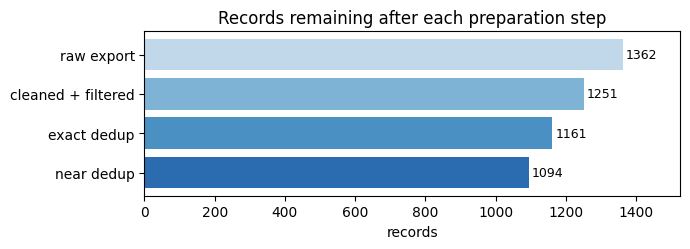

In [5]:
def contamination(train, val, threshold=0.8):
    """Fraction of validation records with a near duplicate (Jaccard >= threshold) in the training set."""
    train_sh = [shingles(record_text(r)) for r in train]
    hits = 0
    for r in val:
        sh = shingles(record_text(r))
        hits += any(jaccard(sh, t) >= threshold for t in train_sh)
    return hits / len(val)


tr_bad, va_bad = train_test_split(filtered, test_size=0.2, random_state=SEED)
tr_ok, va_ok = train_test_split(deduped, test_size=0.2, random_state=SEED)
print(f"split before dedup: {contamination(tr_bad, va_bad):.1%} of validation records have a near copy in training")
print(f"split after dedup:  {contamination(tr_ok, va_ok):.1%}")

stages = [("raw export", len(raw)), ("cleaned + filtered", len(filtered)), ("exact dedup", len(exact)), ("near dedup", len(deduped))]
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh([s for s, _ in stages][::-1], [n for _, n in stages][::-1], color=["#2b6cb0", "#4a90c2", "#7fb3d5", "#c0d8ea"])
for i, (_, n) in enumerate(stages[::-1]):
    ax.text(n + 10, i, str(n), va="center", fontsize=9)
ax.set_xlabel("records"); ax.set_title("Records remaining after each preparation step")
ax.set_xlim(0, len(raw) * 1.12); plt.tight_layout(); plt.show()

**Reading the result.** With the split made before deduplication, about one validation record in five (22%) has a near copy in training, from the duplicated export days and the re-sent complaints. The model's score on those records measures memory, not generalization. After deduplication, no validation record has a near copy in training. Cleaning, filtering, and deduplication together removed about 20% of the export (1,362 → 1,094 records).

The same problem appears at a larger scale as **benchmark contamination**: if test questions are on the web, they may be in a model's pretraining data. When you build an evaluation set for a fine-tuned model, check it against the training data with the same kind of overlap test.

## 5. Splitting by group and formatting for a chat model

**Split by group.** Deduplication removes copies, but records can still be related without being near-identical. Here, the same customer often writes several tickets, in the same style, about the same order. If one is in training and another in validation, validation is easier than real use, where most customers are new. We therefore split **by customer**: all of a customer's tickets go to the same side. This is the same idea as grouping by anchor phrase in the [`Trainer` notebook](../fine_tuning/hf_trainer_fine_tuning.ipynb). `GroupShuffleSplit` does it in one call.

In [6]:
groups = [r["customer_id"] for r in deduped]
train_idx, val_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(deduped, groups=groups))
train_recs = [deduped[i] for i in train_idx]
val_recs = [deduped[i] for i in val_idx]
shared = {r["customer_id"] for r in train_recs} & {r["customer_id"] for r in val_recs}
print(f"train {len(train_recs)} records, validation {len(val_recs)} records, customers on both sides: {len(shared)}")

train 907 records, validation 187 records, customers on both sides: 0


### Formatting with the chat template

A chat model is trained on conversations rendered with its **chat template**: special tokens that mark where each message starts, who is speaking, and where it ends. Qwen2.5 uses ChatML, in which every message is written as `<|im_start|>` and the role on one line, then the content, then `<|im_end|>`. Fine-tuning must use the same template the model will see at inference, so in practice use the one that ships with the tokenizer (`tokenizer.apply_chat_template`). [LLM training stages and chat templates](llm_training_stages.md) explains where the template comes from and what goes wrong without it. Each record becomes three messages: our system prompt, the customer's message (`user`), and the agent's reply (`assistant`).

**Which tokens are trained on.** The template decides what the model sees; the labels decide what it is graded on. As in the [QLoRA lab](../../labs/qlora_dialogsum/qlora_dialogsum_lab.ipynb) (Exercise 2), the loss is computed **only on the reply**: the system prompt, the customer's message and the `<|im_start|>assistant` line get the label `-100`. The model should learn to write replies, not to predict customer complaints. The end-of-turn token `<|im_end|>` after the reply **keeps** its label, for the reason shown in Section 8 of the [GPT-2 notebook](../fine_tuning/gpt2_fine_tuning.ipynb): without it, the model never learns to stop.

The cell below writes ChatML by hand, so that it runs offline and you can see every character. It renders one record from the training split and divides it into the prompt (label `-100`) and the target (trained on).

In [7]:
SYSTEM = "You are a customer-support assistant for a food-delivery app. Be brief, polite, and specific."


def to_messages(rec):
    return [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": rec["message"]},
            {"role": "assistant", "content": rec["reply"]}]


def render_chatml(messages):
    """Prompt part (no loss) and target part (loss) of one training example, in ChatML."""
    prompt = "".join(f"<|im_start|>{m['role']}\n{m['content']}<|im_end|>\n" for m in messages[:-1])
    prompt += "<|im_start|>assistant\n"
    target = messages[-1]["content"] + "<|im_end|>"
    return prompt, target


prompt, target = render_chatml(to_messages(train_recs[0]))
print("PROMPT (label -100):\n" + prompt)
print("TARGET (trained on):\n" + target)

PROMPT (label -100):
<|im_start|>system
You are a customer-support assistant for a food-delivery app. Be brief, polite, and specific.<|im_end|>
<|im_start|>user
good evening my order from bombay bites the dosa was not in the bag i am a regular customer fix this !!<|im_end|>
<|im_start|>assistant

TARGET (trained on):
sorry that an item was missing. we have refunded rs 399 for it to your original payment method. regards, agent asha (<EMAIL>)<|im_end|>


**Reading the output.** Look at the end of the target: `regards, agent asha (<EMAIL>)`. Redaction removed the address, but the assistant would still learn to sign its replies as "Agent Asha", because 5% of replies in the export end with that signature. None of our filters catches this. A rule that strips signatures would, but you only find out that you need it by reading rendered examples, which is why the last step of preparation is always to read some.

**Check lengths before choosing `max_length`.** If a training example is longer than the maximum sequence length, the tokenizer truncates it from the right, which removes the end of the **reply** and its `<|im_end|>` token. Look at the length distribution, choose a maximum that covers nearly every example, and drop or shorten the rest instead of silently truncating. The cell below counts lengths in words to stay offline; set `USE_REAL_TOKENIZER = True` (Kaggle with internet, about 12 MB download) to count real Qwen2.5 tokens and to check that our hand-written template matches the official one.

In [8]:
USE_REAL_TOKENIZER = False      # optional: downloads the Qwen2.5-0.5B-Instruct tokenizer (Apache-2.0)

examples = [render_chatml(to_messages(r)) for r in train_recs]
if USE_REAL_TOKENIZER:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
    official = tok.apply_chat_template(to_messages(train_recs[0]), tokenize=False)
    print("hand-written template matches the official one:", official == prompt + target + "\n")
    lengths = np.array([len(tok(p + t)["input_ids"]) for p, t in examples]); unit = "tokens"
else:
    lengths = np.array([len((p + t).split()) for p, t in examples]); unit = "words"

for q in (50, 95, 99, 100):
    print(f"{q:>3}th percentile: {np.percentile(lengths, q):.0f} {unit}")

 50th percentile: 55 words
 95th percentile: 65 words
 99th percentile: 69 words
100th percentile: 75 words


**Reading the output.** These examples are short (most of each one is the system prompt), so any reasonable `max_length` covers all of them. Real support conversations are not: a long thread can be ten times the median. Choosing `max_length` near the 99th percentile and handling the longest examples explicitly costs little memory and keeps every reply intact. Finally, apply the rule from the GPT-2 notebook: **decode one complete training example together with its labels and read it** before starting a long run.

## 6. Data augmentation

**Data augmentation** creates new training examples from existing ones by changing them in ways that should not change the label (for classification) or the right response (for generation). It is routine for images, where flips and crops rarely change what a picture shows. For text, small edits can change the meaning, so it needs more care. Feng et al. (2021) survey the methods.

| Family | Example | Strength | Main risk |
| --- | --- | --- | --- |
| **Rule-based edits** (EDA, Easy Data Augmentation; Wei & Zou, 2019) | "my order is late" → "my order is delayed" | Free and fast | Context-free edits can change the meaning |
| **Noise** (typos, casing, dropped punctuation) | "delivered" → "deliveerd" | Robustness to messy input | Too much noise makes the text unreadable |
| **Back-translation** (Sennrich et al., 2016) | English → Hindi → English | Natural paraphrases | Translation errors; needs two translation models |
| **Paraphrasing or generating with an LLM** (e.g. Self-Instruct; Wang et al., 2023) | "Rewrite this complaint in five different ways" | Varied, fluent text | Repeats the generator's style and errors; licence terms of the generator |

**EDA (Easy Data Augmentation).** Wei & Zou (2019) proposed four simple word-level edits for text classification. Each one changes a few words in a sentence, the number set as a fraction of the sentence length:

| Operation | What it does | Example on "my order is late and cold" |
| --- | --- | --- |
| **Synonym replacement (SR)** | Picks a few words that are not stop words and replaces each with a random synonym from WordNet | "my order is **delayed** and cold" |
| **Random insertion (RI)** | Takes a synonym of a random word and inserts it at a random position | "my order is late **delayed** and cold" |
| **Random swap (RS)** | Picks two words and swaps their positions | "my **late** is **order** and cold" |
| **Random deletion (RD)** | Removes each word with a small probability | "my order is late cold" ("and" removed) |

None of the four looks at the surrounding words: this is what *context-free* means in the table above. Random insertion and random swap often produce ungrammatical text. Wei & Zou report gains for text classifiers trained on small datasets, where the label usually survives a few odd words. EDA suits generative fine-tuning less well, because a model trained on broken sentences can learn to write them.

The risks deserve specific attention:

- **Label or response drift.** Random deletion can remove "not" ("money **not** deducted" → "money deducted"). A synonym list without context can turn "the **late** delivery" into "the **deceased** delivery", since "late" also means deceased. For generative fine-tuning, there is a further problem: if you augment the customer's message, the original reply must still be a correct answer to it.
- **Synthetic data is not real data.** Training models repeatedly on their own outputs narrows what they produce, a process called **model collapse** (Shumailov et al., 2024). Keep synthetic examples labelled as such, keep a share of real data, and never evaluate on synthetic data alone.
- **Leakage.** Augmented copies of an example are near duplicates of it. Section 7 shows what happens when they cross the split.

The cell below implements synonym replacement and typo noise (swapping two adjacent letters), chained in `augment()`. Its synonym list is small and hand-checked for this domain, instead of WordNet, which also lists senses such as "deceased" for "late". It also shows random deletion changing a meaning. Random insertion and random swap are not implemented.

In [9]:
SYNONYMS = {   # small, hand-checked list for this domain
    "late": ["delayed", "overdue"], "missing": ["not there", "absent"], "refund": ["money back", "reimbursement"],
    "charged": ["billed"], "stale": ["old", "not fresh"], "spoiled": ["rotten", "gone bad"], "sick": ["ill", "unwell"],
    "order": ["food order"], "arrived": ["come"], "wrong": ["incorrect"],
}


def synonym_replace(text, rng, p=0.5):
    return " ".join(rng.choice(SYNONYMS[w]) if w in SYNONYMS and rng.random() < p else w for w in text.split())


def typo_noise(text, rng, p=0.1):
    out = []
    for w in text.split():
        if len(w) > 3 and rng.random() < p:             # swap two adjacent letters
            i = rng.randrange(len(w) - 1); w = w[:i] + w[i + 1] + w[i] + w[i + 2:]
        out.append(w)
    return " ".join(out)


def random_deletion(text, rng, p=0.2):
    kept = [w for w in text.split() if rng.random() > p]
    return " ".join(kept) or text


def augment(text, rng):
    return typo_noise(synonym_replace(text, rng), rng)


rng = random.Random(1)
msg = "hi my order is late and the paneer tikka was stale i want a refund"
for _ in range(3):
    print("augmented:", augment(msg, rng))
risky = "payment failed but money not deducted"
print("\nrandom deletion on:", repr(risky))
for k in range(6):
    out = random_deletion(risky, random.Random(k))
    print(f"   {out!r:45} {'<- meaning changed' if 'not' not in out and 'deducted' in out else ''}")

augmented: hi my food roder is overdue and the paneer tikka was stale i want a reimbursement
augmented: hi my order is ltae and the paneer tikka was not fresh i want a money back
augmented: hi my order is delayed and the paneer tikka was stale i want a refund

random deletion on: 'payment failed but money not deducted'
   'payment failed but money not deducted'       
   'failed but money not deducted'               
   'payment failed not deducted'                 
   'payment failed but money not'                
   'payment but deducted'                        <- meaning changed
   'payment failed but money not deducted'       


### Does augmentation help: an experiment

We test whether augmented training copies improve a ticket classifier, and on what kind of input.

- **Model.** TF-IDF features of words and word pairs, followed by logistic regression.
- **Training data (the rows of the result):**
  - *no augmentation:* 150 tickets;
  - *+2 augmented copies:* the same 150 tickets plus two augmented copies of each (450 in total), made with `augment()` from the cell above.
- **Test data (the columns):** 1,500 new tickets in two forms:
  - *clean test:* as generated;
  - *messy test:* the same tickets passed through `augment()`, to simulate the synonyms and typos that real customers produce. The labels do not change.
- **`augment()` is used twice, for different purposes:** to make extra training copies (the rows), and to simulate untidy customer text in the messy test set (the columns). The test sets are the same for every model.
- **Repetition.** A single run of a small experiment is noisy, so we repeat it with 8 different training sets of 150 tickets. In each run, both models are trained on the same 150 tickets.
- **Metric.** The mean and standard deviation of the **macro-F1** score over the 8 runs (defined in Section 8; here it is enough that higher is better).

In [10]:
def fit_and_score(train_x, train_y, tests):
    vec = TfidfVectorizer(ngram_range=(1, 2))
    clf = LogisticRegression(C=10, solver="liblinear").fit(vec.fit_transform(train_x), train_y)
    return [f1_score(y, clf.predict(vec.transform(x)), average="macro") for x, y in tests]


test_x, test_y = make_tickets(1500, seed=2)
rng = random.Random(5)
messy_x = [augment(t, rng) for t in test_x]
tests = [(test_x, test_y), (messy_x, test_y)]

scores = {"no augmentation": [], "+2 augmented copies": []}
for run in range(8):
    tx, ty = make_tickets(150, seed=100 + run)
    rng = random.Random(run)
    scores["no augmentation"].append(fit_and_score(tx, ty, tests))
    aug_x = [augment(t, rng) for t in tx for _ in range(2)]
    aug_y = [y for y in ty for _ in range(2)]
    scores["+2 augmented copies"].append(fit_and_score(tx + aug_x, ty + aug_y, tests))

print(f"{'training data':<22}{'clean test':>18}{'messy test':>18}")
for name, s in scores.items():
    s = np.array(s)
    print(f"{name:<22}{s[:, 0].mean():>11.3f} ± {s[:, 0].std():.3f}{s[:, 1].mean():>11.3f} ± {s[:, 1].std():.3f}")
gain = np.array(scores["+2 augmented copies"]) - np.array(scores["no augmentation"])   # same training set, with and without
print(f"{'gain (paired)':<22}{gain[:, 0].mean():>+11.3f} ± {gain[:, 0].std():.3f}{gain[:, 1].mean():>+11.3f} ± {gain[:, 1].std():.3f}")
print(f"runs where augmentation helped: clean {(gain[:, 0] > 0).sum()}/8, messy {(gain[:, 1] > 0).sum()}/8")

training data                 clean test        messy test
no augmentation             0.628 ± 0.032      0.561 ± 0.032
+2 augmented copies         0.658 ± 0.036      0.610 ± 0.039
gain (paired)              +0.030 ± 0.012     +0.049 ± 0.018
runs where augmentation helped: clean 8/8, messy 8/8


**Reading the experiment results.**

- **First two rows (mean ± standard deviation).** Augmentation raises macro-F1 from 0.628 to 0.658 on the clean test and from 0.561 to 0.610 on the messy test. But the spread between training sets (about ±0.035) is as large as these differences, so comparing the two rows alone is inconclusive.
- **Paired gain (third row).** The useful comparison is within each run: the same 150 tickets with and without augmentation. This removes the luck of which tickets were drawn, so the spread is much smaller (±0.012 and ±0.018). Augmentation helps in all 8 runs on both test sets.
- **Clean versus messy.** The gain is larger on the messy test (+0.049) than on the clean test (+0.030), because the messy test contains exactly the variation (synonyms, typos) that the augmentation simulates. This is the most favourable case for augmentation; do not expect gains this large on real text whose variation differs from it.
- **The general lesson.** Augmentation encodes an assumption about how real inputs vary. It helps when that assumption is right, and it adds nothing (or adds noise) when it is not. You can only check the assumption with test data that resembles real use.
- **Amount of real data.** The gain shrinks as real data grows. With thousands of real examples, rule-based augmentation rarely matters; it is most useful for small datasets and for rare categories.

## 7. Augment after the split, not before

Augmented copies of a ticket are near duplicates of it. If you augment the whole dataset and **then** split it, copies of a validation ticket end up in training, and the model is graded on examples it has effectively seen.

The effect is largest when the model can memorize something it could not otherwise predict, and real labels always contain some errors.

### Augment before or after the split: an experiment

We train the same classifier with the two orders of augmenting and splitting, and check which validation score can be trusted.

- **Model.** The TF-IDF and logistic regression classifier from Section 6, scored by **accuracy**.
- **Data.** 600 tickets per run. We simulate annotation errors by giving 20% of them a random category (by chance, sometimes the correct one). A wrong label cannot be predicted from the text; it can only be memorized.
- **Two pipelines (A and B in the result).** Both train on 2,250 tickets; only the order of the two steps differs:
  - *A (wrong):* augment every ticket 4 times (600 → 3,000 tickets), then split 75/25 into 2,250 training and 750 validation tickets;
  - *B (right):* split 75/25 into 450 training and 150 validation tickets, then augment only the training tickets 4 times (450 → 2,250).
- **Two evaluation sets (val and fresh in the result):**
  - *val:* each pipeline's own validation split, the score it would report;
  - *fresh:* 2,000 new tickets labelled by the same noisy process, the same for both pipelines. They stand in for future real data, so a trustworthy validation score should be close to the fresh score.
- **Repetition.** 3 runs (seeds 0–2), each with a new set of 600 tickets.

In [11]:
def noisy_labels(labels, rng, rate=0.2):
    return [rng.choice(NAMES) if rng.random() < rate else y for y in labels]


def train_and_score(train_x, train_y, evals):
    vec = TfidfVectorizer(ngram_range=(1, 2))
    clf = LogisticRegression(C=10, solver="liblinear").fit(vec.fit_transform(train_x), train_y)
    return [accuracy_score(y, clf.predict(vec.transform(x))) for x, y in evals]


def expand(xs, ys, rng, copies=4):
    return xs + [augment(t, rng) for t in xs for _ in range(copies)], ys + [y for y in ys for _ in range(copies)]


fresh_x, fresh_y = make_tickets(2000, seed=999)
fresh_y = noisy_labels(fresh_y, random.Random(999))
print(f"{'seed':<6}{'A: val':>10}{'A: fresh':>10}{'B: val':>10}{'B: fresh':>10}")
for seed in range(3):
    rng = random.Random(seed)
    x, y = make_tickets(600, seed=50 + seed)
    y = noisy_labels(y, rng)
    ax_, ay_ = expand(x, y, rng)                                                     # A: augment, then split
    a_tr_x, a_va_x, a_tr_y, a_va_y = train_test_split(ax_, ay_, test_size=0.25, random_state=seed)
    a = train_and_score(a_tr_x, a_tr_y, [(a_va_x, a_va_y), (fresh_x, fresh_y)])
    b_tr_x, b_va_x, b_tr_y, b_va_y = train_test_split(x, y, test_size=0.25, random_state=seed)   # B: split, then augment
    b_tr_x, b_tr_y = expand(b_tr_x, b_tr_y, rng)
    b = train_and_score(b_tr_x, b_tr_y, [(b_va_x, b_va_y), (fresh_x, fresh_y)])
    print(f"{seed:<6}{a[0]:>10.3f}{a[1]:>10.3f}{b[0]:>10.3f}{b[1]:>10.3f}")

seed      A: val  A: fresh    B: val  B: fresh


0          0.891     0.755     0.660     0.735


1          0.921     0.765     0.767     0.743


2          0.933     0.750     0.780     0.719


**Reading the experiment results.** The mean accuracy over the three runs, computed from the rows above, and the gap between each pipeline's validation and fresh means (how much its validation score overstates its accuracy on new data):

| | A: val | A: fresh | B: val | B: fresh |
| --- | --- | --- | --- | --- |
| **mean of 3 runs** | 0.915 | 0.757 | 0.736 | 0.732 |
| **gap (val − fresh)** | +0.158 | | +0.004 | |

- **A's validation score is inflated.** A reports about 0.92 on validation (0.891–0.933) but scores about 0.76 on fresh tickets, an overstatement of about 0.16.
- **Why.** A's validation set contains augmented copies of training tickets, *with the same wrong labels*. The model has memorized those labels from the training copies, so it gets them "right" in validation. On fresh tickets the wrong labels are new and cannot be memorized.
- **B's validation score is honest.** B's validation scores (0.660–0.780) scatter around its fresh scores (about 0.73), because its validation set has only 150 tickets. The scatter is noise, not bias: averaged over the runs, validation and fresh agree (0.736 and 0.732).
- **The models are about equally good.** On fresh tickets A and B score about the same (0.757 and 0.732). The pipelines differ in what they report, not in the quality of the model they produce.
- **Why fresh accuracy is only about 0.75.** About 16% of the fresh labels are wrong (20% are random, and one in five of those is correct by chance), so a classifier that always predicted the true category would score only about 0.84.
- **The general rule.** The same applies to every transformation that learns from or copies data: split first, then fit normalizers, build vocabularies, augment, or oversample, using the training split only.

## 8. Imbalanced data: the accuracy trap

Our categories are imbalanced: `late_delivery` is about 18 times more frequent than `food_safety`. That is normal. Fraud, rare diseases, and safety complaints are rare by nature, and they are usually the cases that matter most.

**Why accuracy misleads.** A model that always predicts `late_delivery` is right on 55% of tickets and useless. A model can reach high accuracy while missing every food-safety complaint, because those are only 3% of the score. Use metrics that look at each class:

| Metric | Definition for class $c$ | Question it answers |
| --- | --- | --- |
| **Precision** | $\frac{TP_c}{TP_c + FP_c}$ | When the model says $c$, how often is it right? |
| **Recall** | $\frac{TP_c}{TP_c + FN_c}$ | Of the real $c$ tickets, how many did the model find? |
| **F1** | $\frac{2 \cdot P_c \cdot R_c}{P_c + R_c}$ | A single number that is low if either is low |
| **Macro-F1** | mean of F1 over classes | Every class counts equally, however rare |

Here $TP_c$, $FP_c$, $FN_c$ are the true positives, false positives, and false negatives for class $c$. For the router, the number that matters most is **recall on `food_safety`**: a missed food-safety complaint is far more costly than an unnecessary escalation.

**Stratified splits.** With few rare examples, a random split can put very different numbers of them into validation, and the validation recall for the rare class then depends on luck. A **stratified** split keeps each class's share the same in both parts.

In [5]:
X_all, y_all = make_tickets(2000, seed=0)
counts = Counter(y_all)
print("category counts:", {c: counts[c] for c in NAMES})
print(f"majority-class accuracy: {counts['late_delivery'] / len(y_all):.3f}\n")

random_counts = [Counter(train_test_split(y_all, test_size=0.3, random_state=s)[1])["food_safety"] for s in range(20)]
strat_counts = [Counter(train_test_split(y_all, test_size=0.3, random_state=s, stratify=y_all)[1])["food_safety"] for s in range(20)]
print("food_safety tickets in a 30% validation set, over 20 random seeds")
print(f"   random split:     min {min(random_counts)}, max {max(random_counts)}")
print(f"   stratified split: min {min(strat_counts)}, max {max(strat_counts)}")

category counts: {'late_delivery': 1096, 'missing_item': 436, 'payment': 239, 'refund': 169, 'food_safety': 60}
majority-class accuracy: 0.548

food_safety tickets in a 30% validation set, over 20 random seeds
   random split:     min 11, max 24
   stratified split: min 18, max 18


**Reading the output.** With a random split, the number of food-safety tickets in validation ranges from 11 to 24 across seeds. Stratification gives 18 every time. Even then, 18 is a small number, so each one changes the measured recall by more than 5 percentage points. Report rare-class results with that uncertainty in mind, and use stratified K-fold cross-validation when the data is small.

## 9. Remedies: class weights and oversampling

Training with cross-entropy minimizes the **average** loss over examples. With 55% `late_delivery` tickets, most gradient steps are about late deliveries, and a model can lower the average loss a lot while getting rare classes wrong. There are two standard fixes, which change the same average in different ways:

1. **Class weights.** Multiply each example's loss by a weight $w_c$ for its class, with larger weights for rarer classes. A common choice is $w_c = \frac{N}{K \cdot n_c}$, for $N$ examples, $K$ classes, and $n_c$ examples in class $c$, so that every class contributes equally to the total. In PyTorch this is `nn.CrossEntropyLoss(weight=w)`; scikit-learn calls it `class_weight="balanced"`.
2. **Oversampling.** Draw training batches so that rare classes appear more often, for example with probability proportional to $1/n_c$ (PyTorch's `WeightedRandomSampler`). The loss is unweighted, but rare examples are **repeated**, so the model sees the same few food-safety tickets many times. Undersampling (dropping common examples) has the same effect, but discards data.

**Why these weights balance the classes.** Multiplying both sides of $w_c = \frac{N}{K \cdot n_c}$ by $n_c$ gives $w_c \cdot n_c = \frac{N}{K}$: every class gets the same **total weight**, however many examples it has. With the training split used in the experiment below ($N = 1{,}400$ tickets, $K = 5$ classes, so $N/K = 280$):

| Class | $n_c$ | $w_c = 1400 / (5 \cdot n_c)$ | Total weight $w_c \cdot n_c$ |
| --- | --- | --- | --- |
| `late_delivery` | 767 | 0.365 | 280 |
| `missing_item` | 305 | 0.918 | 280 |
| `payment` | 167 | 1.677 | 280 |
| `refund` | 119 | 2.353 | 280 |
| `food_safety` | 42 | 6.667 | 280 |

- **Unweighted**, each class's share of the loss is roughly its share of the data: 55% for `late_delivery`, 3% for `food_safety`. **Weighted**, each class carries 280 of the 1,400 total, a fifth each. Oversampling with probability proportional to $1/n_c$ reaches the same one-fifth share by repeating examples instead of scaling their losses.
- **Equal weight is not equal loss.** A class's actual contribution is its total weight times its average per-example loss, so a class the model handles badly still contributes more. The weights only remove the advantage of being frequent.
- **Only the ratios matter.** With `weight=`, PyTorch's `cross_entropy` divides by the sum of the weights in the batch, so multiplying all weights by 10 changes nothing. The factor $N/K$ just keeps the weights near 1.

Two more remedies are worth knowing. **Focal loss** (Lin et al., 2017) down-weights examples the model already classifies confidently, which focuses training on hard and rare cases. **Threshold moving** keeps the model and changes the decision rule, for example flagging food safety whenever its predicted probability exceeds 0.2 instead of picking the most probable class. Resampling methods for numeric features such as SMOTE (Chawla et al., 2002) interpolate between examples and do not apply directly to text.

### Class weights versus oversampling: an experiment

We train the same router three ways and compare how well each one finds the rare food-safety complaints.

- **Model.** A linear layer on TF-IDF features of words and word pairs (a multinomial logistic regression), trained with PyTorch so that the loss and the sampler are visible in the code: SGD, 3,000 steps, batches of 64 tickets.
- **Data.** The 2,000 tickets from Section 8, split 70/30 with stratification into 1,400 training and 600 validation tickets. Food safety has 42 training and 18 validation tickets.
- **Three training methods (the rows of the result).** The model, data, seed, and number of steps are identical; only the loss weights or the sampling change:
  - *plain cross-entropy:* batches drawn uniformly, and every example's loss counts equally;
  - *class weights:* the same sampling, with each example's loss multiplied by $w_c = \frac{N}{K \cdot n_c}$. The cell prints the weights: from 0.37 for `late_delivery` to 6.67 for `food_safety`;
  - *oversampling:* an unweighted loss, but each example is drawn with probability proportional to $1/n_c$, so each class makes up about a fifth of every batch.
- **Metrics (the columns):** accuracy, macro-F1, and the recall and precision of `food_safety`, all on the validation split. The next cell shows the validation confusion matrices for plain cross-entropy and class weights.
- **A single run.** Unlike Sections 6 and 7, this is one run on one split; the last bullet of the results says what that means for the numbers.

**How batches are drawn.** Each of the 3,000 steps draws a fresh batch of 64 row indices from the 1,400 training tickets, with replacement, so a row can appear in many batches (and occasionally twice in one). Validation tickets are never sampled. The two sampling modes in `train_router` differ only in how likely each row is to be picked:

| | `torch.randint(len(y_tr_t), (64,))` | `torch.multinomial(sample_p, 64, replacement=True)` |
| --- | --- | --- |
| **Draws** | 64 row indices from 0 to 1,399 | 64 row indices from 0 to 1,399 |
| **Probability of row $i$** | the same for every row: 1/1,400 | proportional to its weight `sample_p[i]` |
| **Effect on classes** | each class at its natural share (55% late, 3% food safety) | each class at about a fifth of every batch |
| **Used for** | plain cross-entropy and class weights | oversampling |

Here `sample_p = (1 / n_c)[y_tr_t]` gives each row the weight $1/n_c$ of its class, so every class has a total weight of $n_c \cdot \frac{1}{n_c} = 1$. This is the same equal-total-weight idea as class weights, applied to the sampling instead of the loss. `replacement=True` lets a row be drawn more than once, which is how 42 food-safety tickets can fill a fifth of every batch.

In [6]:
X_tr, X_va, y_tr, y_va = train_test_split(X_all, [NAMES.index(c) for c in y_all], test_size=0.3, stratify=y_all, random_state=SEED)
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
A_tr = torch.tensor(vec.fit_transform(X_tr).toarray(), dtype=torch.float32)
A_va = torch.tensor(vec.transform(X_va).toarray(), dtype=torch.float32)
y_tr_t, y_va_np = torch.tensor(y_tr), np.array(y_va)
n_c = torch.bincount(y_tr_t, minlength=len(NAMES)).float()
class_weights = n_c.sum() / (len(NAMES) * n_c)                      # N / (K * n_c)
print("training counts:", n_c.int().tolist())
print("class weights:  ", [round(w, 2) for w in class_weights.tolist()])


def train_router(weight=None, oversample=False, steps=3000, batch_size=64, lr=0.5, seed=SEED):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    model = nn.Linear(A_tr.shape[1], len(NAMES))
    opt = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=1e-3)
    sample_p = (1 / n_c)[y_tr_t]                                      # per-example probability for oversampling
    for _ in range(steps):
        if oversample:
            idx = torch.multinomial(sample_p, batch_size, replacement=True, generator=g)
        else:
            idx = torch.randint(len(y_tr_t), (batch_size,), generator=g)
        loss = F.cross_entropy(model(A_tr[idx]), y_tr_t[idx], weight=weight)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return model(A_va).argmax(1).numpy()


preds = {"plain cross-entropy": train_router(),
         "class weights": train_router(weight=class_weights),
         "oversampling": train_router(oversample=True)}
fs = NAMES.index("food_safety")
print(f"\n{'method':<22}{'accuracy':>9}{'macro-F1':>10}{'food_safety recall':>20}{'food_safety precision':>23}")
for name, p in preds.items():
    print(f"{name:<22}{accuracy_score(y_va_np, p):>9.3f}{f1_score(y_va_np, p, average='macro'):>10.3f}"
          f"{recall_score(y_va_np, p, labels=[fs], average=None)[0]:>20.2f}"
          f"{precision_score(y_va_np, p, labels=[fs], average=None, zero_division=0)[0]:>23.2f}")

training counts: [767, 305, 167, 119, 42]
class weights:   [0.37, 0.92, 1.68, 2.35, 6.67]

method                 accuracy  macro-F1  food_safety recall  food_safety precision
plain cross-entropy       0.930     0.768                0.06                   1.00
class weights             0.910     0.874                0.89                   0.70
oversampling              0.912     0.870                0.89                   0.64


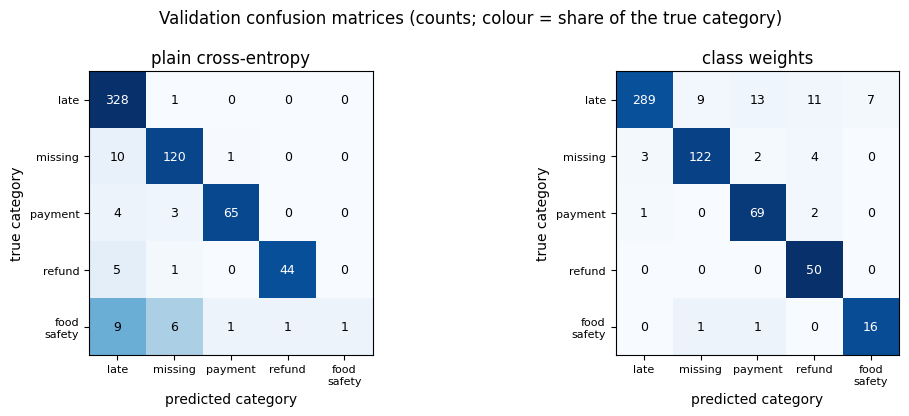

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
short = ["late", "missing", "payment", "refund", "food\nsafety"]
for ax, name in zip(axes, ["plain cross-entropy", "class weights"]):
    cm = confusion_matrix(y_va_np, preds[name], labels=range(len(NAMES)))
    ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(len(NAMES)):
        for j in range(len(NAMES)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9, color="white" if cm[i, j] / cm[i].sum() > 0.6 else "black")
    ax.set_xticks(range(len(NAMES)), short, fontsize=8); ax.set_yticks(range(len(NAMES)), short, fontsize=8)
    ax.set_xlabel("predicted category"); ax.set_ylabel("true category"); ax.set_title(name)
fig.suptitle("Validation confusion matrices (counts; colour = share of the true category)")
plt.tight_layout(); plt.show()

**Reading the experiment results.**

- **Plain cross-entropy misses the rare class.** It has the highest accuracy (0.930), yet finds only 1 of the 18 food-safety complaints (recall 0.06). The confusion matrix shows where the rest went: 9 to `late_delivery` and 6 to `missing_item`, the two most common categories. Its precision of 1.00 only says that its single food-safety prediction was right.
- **Both remedies find the rare class.** Class weights and oversampling each find 16 of the 18 (recall 0.89).
- **The price is false alarms.** Precision on `food_safety` falls to 0.70 with class weights and 0.64 with oversampling. The class-weights confusion matrix shows the 7 false alarms are all late-delivery tickets.
- **Errors move rather than disappear.** Accuracy drops only slightly, to about 0.91: class weights make 54 errors on the 600 validation tickets against 42 for plain cross-entropy. Most errors are now late-delivery tickets sent to other categories, instead of rare tickets sent to `late_delivery`.
- **Macro-F1 rises** from 0.768 to about 0.87, because it counts the rare class as much as the common ones.
- **Choosing a model.** Neither summary number tells you which model to deploy. That depends on the cost of each kind of error. Here, a missed food-safety complaint is worse than an unnecessary escalation, so we accept lower precision for higher recall.
- **Caveat: one small run.** With only 18 food-safety tickets, each one moves the recall by 0.06, and a different seed or split would give somewhat different numbers. The small differences between class weights and oversampling are within that noise. Check per-class metrics, not just the average, every time.

## 10. Imbalance when fine-tuning a generative model

The support assistant has the same problem in a different form. If 3% of conversations are about food safety, the assistant gets little practice at its most delicate reply: apologizing, escalating, and suggesting medical advice. There is no single "class" output to weight, so the usual fix is to change **how often each category is sampled** into training batches.

A standard recipe is **temperature sampling**, used for example to mix languages when training multilingual models (mT5 used $\alpha = 0.3$; Xue et al., 2021). Category $c$ with $n_c$ examples is sampled with probability

$$p_c = \frac{n_c^{\alpha}}{\sum_k n_k^{\alpha}}, \qquad 0 \le \alpha \le 1.$$

With $\alpha = 1$ we sample in natural proportions; with $\alpha = 0$ every category is equally likely; values in between raise rare categories without making them dominate. The cost is **repetition**: the rare examples are seen many more times, and a small set repeated too often is memorized. Muennighoff et al. (2023) found that up to about four epochs of repeated data were almost as useful as fresh data for pretraining, with returns falling quickly after that. The table shows how many times each food-safety example is repeated if we draw 3,000 training examples from our deduplicated training split.

In [15]:
cat_counts = Counter(r["category"] for r in train_recs)
n = np.array([cat_counts[c] for c in NAMES], dtype=float)
BUDGET = 3000                                   # training examples drawn in total
print(f"{'category':<15}{'examples':>9}" + "".join(f"{'α=' + str(a):>9}" for a in (1, 0.5, 0.3, 0)))
for i, c in enumerate(NAMES):
    row = f"{c:<15}{int(n[i]):>9}"
    for alpha in (1, 0.5, 0.3, 0):
        p = n ** alpha / (n ** alpha).sum()
        row += f"{p[i]:>9.1%}"
    print(row)
fs = NAMES.index("food_safety")
repeats = [BUDGET * (n ** a / (n ** a).sum()) / n for a in (1, 0.5, 0.3, 0)]
print(f"\n{'times each example is seen in ' + str(BUDGET) + ' draws':<34}" + "".join(f"{'α=' + str(a):>9}" for a in (1, 0.5, 0.3, 0)))
for i in (0, fs):
    print(f"   {NAMES[i]:<31}" + "".join(f"{r[i]:>9.1f}" for r in repeats))

category        examples      α=1    α=0.5    α=0.3      α=0
late_delivery        492    54.2%    36.7%    29.6%    20.0%
missing_item         212    23.4%    24.1%    23.0%    20.0%
payment               99    10.9%    16.5%    18.3%    20.0%
refund                82     9.0%    15.0%    17.3%    20.0%
food_safety           22     2.4%     7.8%    11.7%    20.0%

times each example is seen in 3000 draws      α=1    α=0.5    α=0.3      α=0
   late_delivery                        3.3      2.2      1.8      1.2
   food_safety                          3.3     10.6     15.9     27.3


**Reading the output.** At $\alpha = 1$ food safety is 2.4% of training. At $\alpha = 0$ it gets a fifth of all draws, but each of its 22 examples is seen about 27 times, against about once for a late-delivery example. $\alpha = 0.3$ raises the share to about 12% at the cost of roughly 16 repeats, already well beyond the four-epoch range above, so watch for memorization: replies to food-safety prompts that copy training replies word for word. Whatever you choose, evaluate the assistant **separately for each category**. An average quality score can look fine while the rare category is poor.

If the rare category is too small to repeat safely, this is where careful augmentation (Section 6) is most valuable: a few hundred reviewed paraphrases of real food-safety complaints, kept in the training split only.

## 11. Summary

| Stage | Do | Check |
| --- | --- | --- |
| Normalize, redact, filter | Unescape and strip markup, NFKC, placeholders for personal data, drop empty and automated replies | Read a sample of what each rule removes or changes |
| Deduplicate | Exact hashes, then near duplicates (shingles + Jaccard, or MinHash at scale), **before** splitting | Overlap between validation and training is (near) zero |
| Split | By group (customer, conversation, document), stratified for rare classes | No group on both sides; class shares match |
| Format | The model's own chat template; loss on the reply and its end-of-turn token only | Decode one example with its labels; check the length distribution |
| Augment | Training split only; transformations that preserve the label or response; label synthetic data | Gains on a test set that resembles real use, over several seeds |
| Handle imbalance | Class weights, oversampling, or temperature sampling; choose by the cost of each error | Per-class recall and precision, not only accuracy or an average |

A short written record of these choices (data source, licence, filters, counts at each step, known gaps) is a **datasheet** for the dataset (Gebru et al., 2021). It is what lets someone else, or you in three months, trust and reproduce the training data.

## 12. Check your understanding

1. In Section 4, why did we mask digits before computing shingles? Give an example of a pair of records that would be missed without it, and one kind of record for which masking digits could wrongly merge two different examples.
2. A colleague deduplicates the training split and the validation split separately. What problem does this leave, and how would you detect it?
3. Why do we redact personal data with placeholders such as `<PHONE>` rather than deleting it? What can a regular expression not catch? Write a rule that removes the agent signature found in Section 5, and say how you would check that it removes nothing else.
4. In the chat format, which tokens get the label `-100`, and why does `<|im_end|>` after the reply keep its label?
5. Give one augmentation that preserves the label of a ticket but would make the stored reply wrong for a generative assistant.
6. Explain, in terms of what the model memorizes, why Pipeline A in Section 7 overestimates accuracy. Would the gap be larger or smaller with no label noise? Why?
7. A router reaches 97% accuracy on a dataset where 96% of tickets are `late_delivery`. What two numbers would you ask for before believing it is useful?
8. With $w_c = N / (K n_c)$, compute the weights for three classes with 600, 300, and 100 examples. Check that each class then contributes equally to the summed loss.
9. Class weights and oversampling both raise the importance of rare examples. Give one practical difference between them (consider the number of distinct examples per batch and the risk of memorization).
10. For temperature sampling with $\alpha = 0$, a category with 30 examples, 5 categories, and a budget of 3,000 draws: how many times is each of its examples seen? What risk does this create, and what would you try instead?

## References

- Broder, A. Z. (1997). On the resemblance and containment of documents. *Proceedings of Compression and Complexity of Sequences*, 21–29.
- Carlini, N., Tramèr, F., Wallace, E., et al. (2021). Extracting training data from large language models. *USENIX Security Symposium*. [arXiv:2012.07805](https://arxiv.org/abs/2012.07805)
- Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research*, 16, 321–357.
- Feng, S. Y., Gangal, V., Wei, J., et al. (2021). A survey of data augmentation approaches for NLP. *Findings of ACL-IJCNLP 2021*. [arXiv:2105.03075](https://arxiv.org/abs/2105.03075)
- Gebru, T., Morgenstern, J., Vecchione, B., et al. (2021). Datasheets for datasets. *Communications of the ACM*, 64(12), 86–92. [arXiv:1803.09010](https://arxiv.org/abs/1803.09010)
- Lee, K., Ippolito, D., Nystrom, A., et al. (2022). Deduplicating training data makes language models better. *ACL 2022*. [arXiv:2107.06499](https://arxiv.org/abs/2107.06499)
- Lin, T.-Y., Goyal, P., Girshick, R., He, K., & Dollár, P. (2017). Focal loss for dense object detection. *ICCV 2017*. [arXiv:1708.02002](https://arxiv.org/abs/1708.02002)
- Muennighoff, N., Rush, A. M., Barak, B., et al. (2023). Scaling data-constrained language models. *NeurIPS 2023*. [arXiv:2305.16264](https://arxiv.org/abs/2305.16264)
- Sennrich, R., Haddow, B., & Birch, A. (2016). Improving neural machine translation models with monolingual data. *ACL 2016*. [arXiv:1511.06709](https://arxiv.org/abs/1511.06709)
- Shumailov, I., Shumaylov, Z., Zhao, Y., et al. (2024). AI models collapse when trained on recursively generated data. *Nature*, 631, 755–759.
- Wang, Y., Kordi, Y., Mishra, S., et al. (2023). Self-Instruct: Aligning language models with self-generated instructions. *ACL 2023*. [arXiv:2212.10560](https://arxiv.org/abs/2212.10560)
- Wei, J., & Zou, K. (2019). EDA: Easy data augmentation techniques for boosting performance on text classification tasks. *EMNLP-IJCNLP 2019*. [arXiv:1901.11196](https://arxiv.org/abs/1901.11196)
- Xue, L., Constant, N., Roberts, A., et al. (2021). mT5: A massively multilingual pre-trained text-to-text transformer. *NAACL 2021*. [arXiv:2010.11934](https://arxiv.org/abs/2010.11934)
- Zhou, C., Liu, P., Xu, P., et al. (2023). LIMA: Less is more for alignment. *NeurIPS 2023*. [arXiv:2305.11206](https://arxiv.org/abs/2305.11206)